# Recommendations

Purchase history with ratings, from `data/sample_history.json`: made-up data shaped like the item service's `History` (with its `Item`) and `Review` models. Regenerate or resize it with `python3 data/make_sample_history.py [count]`.

In [1]:
import json
from pathlib import Path

import pandas as pd

raw = json.loads(Path("data/sample_history.json").read_text(encoding="utf-8"))
print(f"{len(raw)} purchases, {sum(h['review'] is not None for h in raw)} rated")

60 purchases, 48 rated


## One row per purchase

The item's and the review's fields flattened next to the history's; `score` and `content` are empty for purchases not rated yet.

In [2]:
history = pd.json_normalize(raw).drop(columns=["item.id", "review", "review.id", "review.history_id"], errors="ignore")
history.columns = [c.split(".", 1)[1] if c.startswith(("item.", "review.")) else c for c in history.columns]
history = history.rename(columns={"id": "history_id"})
for col in ["time", "created_at", "deadline_at", "buy_at", "schedule"]:
    history[col] = pd.to_datetime(history[col])
history["score"] = history["score"].astype("Int64")

history[["time", "owner", "item_type", "item_name", "shop_name", "score", "content"]].head(10)

,time,owner,item_type,item_name,shop_name,score,content
0,2026-11-24 22:17:00+07:00,lan,food_and_drink,Trà đào cam sả,Highlands Coffee,<NA>,NaN
1,2026-11-20 19:43:20+07:00,lan,food_and_drink,Trà sữa trân châu đường đen,Phúc Long,5,"Hoàn hảo, không chê được gì"
2,2026-11-10 07:09:07+07:00,lan,food_and_drink,Cà phê muối,Cà Phê Muối Chú Long,3,"Bình thường, không có gì đặc biệt"
3,2026-11-09 15:45:20+07:00,minh,restaurant,Lẩu Thái Tomyum,None,5,"Hoàn hảo, không chê được gì"
4,2026-11-07 16:26:20+07:00,lan,clothes,Túi tote canvas,Shopee,4,"Ngon, sẽ quay lại"
5,2026-10-30 07:21:44+07:00,lan,food_and_drink,Cà phê muối,Cà Phê Muối Chú Long,4,"Ngon, sẽ quay lại"
6,2026-10-26 21:07:22+07:00,lan,restaurant,Bún chả Hương Liên,None,4,"Ngon, sẽ quay lại"
7,2026-10-17 21:16:21+07:00,lan,food_and_drink,Trà sữa trân châu đường đen,Phúc Long,<NA>,NaN
8,2026-10-17 11:17:43+07:00,minh,clothes,Áo hoodie nỉ,Uniqlo Đồng Khởi,4,"Ngon, sẽ quay lại"
9,2026-10-15 11:14:18+07:00,lan,restaurant,Sushi Hokkaido Sachi,None,3,"Ổn, nhưng có chỗ khác ngon hơn"


## Ratings

The rated purchases only, and each person's average score per item: the user–item matrix a recommender starts from.

In [3]:
ratings = history.dropna(subset=["score"])[["owner", "item_type", "item_name", "score"]]
ratings.groupby(["owner", "item_type"])["score"].agg(["count", "mean"]).round(2)

count  mean
owner item_type                  
lan   clothes            11  3.73
      food_and_drink     12  4.08
      others              2   4.0
      restaurant          6   4.0
minh  clothes             8  3.75
      food_and_drink      5   4.0
      others              2   2.5
      restaurant          2   5.0

In [4]:
matrix = ratings.pivot_table(index="owner", columns="item_name", values="score", aggfunc="mean").round(1)
matrix

item_name,Bánh flan caramel,Bánh tráng trộn,Bún chả Hương Liên,Cà phê muối,Giày Air Force 1,Gogi House,Gấu bông Capybara,Lẩu Thái Tomyum,Matcha latte,Nến thơm vanilla,...,Son kem lì,Sushi Hokkaido Sachi,Trà sữa trân châu đường đen,Trà đào cam sả,Túi tote canvas,Váy hoa nhí,Áo hoodie nỉ,Áo sơ mi linen,Áo thun oversize,Ốp lưng điện thoại
owner,,,,,,,,,,,,,,,,,,,,,
lan,<NA>,3.5,4.0,3.5,3.0,5.0,<NA>,3.0,4.5,4.0,...,<NA>,3.0,4.8,<NA>,4.0,4.0,4.5,3.0,4.0,4.0
minh,3.0,<NA>,<NA>,<NA>,4.5,<NA>,3.0,5.0,4.0,<NA>,...,2.0,<NA>,4.0,4.0,2.0,<NA>,4.0,3.0,4.0,<NA>


## Language: Vietnamese or English

Vietnamese is told apart by its letters: â ă đ ê ô ơ ư and the vowels carrying a tone mark. A text with any of them is Vietnamese, anything else English. (An English word with é, like café, counts as Vietnamese.)

In [5]:
import re
import unicodedata

VIETNAMESE = re.compile(
    r"[àáạảãâầấậẩẫăằắặẳẵèéẹẻẽêềếệểễìíịỉĩòóọỏõôồốộổỗơờớợởỡùúụủũưừứựửữỳýỵỷỹđ]", re.IGNORECASE
)


def language(text: str) -> str:
    """'vi' when the text has a Vietnamese letter, else 'en'. NFC first, so a letter typed as
    base + combining mark (as some keyboards do) is one character again."""
    return "vi" if VIETNAMESE.search(unicodedata.normalize("NFC", text)) else "en"


assert language("Trà sữa trân châu") == "vi" and language("ĐÀ NẴNG") == "vi"
assert language("Pizza 4P's") == "en" and language("So good, thank you!") == "en"

history["name_lang"] = history["item_name"].map(language)
history["content_lang"] = history["content"].map(lambda t: language(t) if isinstance(t, str) and t else None)
pd.concat({"item_name": history["name_lang"].value_counts(), "content": history["content_lang"].value_counts()}, axis=1)

,item_name,content
vi,51,35.0
en,9,NaN


## Embeddings

Each text goes to its language's model: [PhoBERT](https://huggingface.co/vinai/phobert-base-v2) for Vietnamese, [ModernBERT](https://huggingface.co/answerdotai/ModernBERT-base) for English. Its vector is the mean of the model's last hidden states over the text's tokens (768 numbers for both).

PhoBERT was trained on word-segmented text (`trà_sữa trân_châu`), so Vietnamese is segmented first, with underthesea. The two models' vectors are in different spaces: compare a Vietnamese text only with other Vietnamese ones, and an English one with English ones.

In [6]:
import numpy as np
import torch
from transformers import AutoModel, AutoTokenizer
from underthesea import word_tokenize

MODELS = {"vi": "vinai/phobert-base-v2", "en": "answerdotai/ModernBERT-base"}
loaded = {}  # language -> (tokenizer, model), downloaded the first time


def model_for(lang):
    if lang not in loaded:
        loaded[lang] = AutoTokenizer.from_pretrained(MODELS[lang]), AutoModel.from_pretrained(MODELS[lang]).eval()
    return loaded[lang]


@torch.no_grad()
def embed(texts, lang, batch_size=16):
    """One vector per text, all in the one language"""
    if lang == "vi":
        texts = [word_tokenize(t, format="text") for t in texts]
    tokenizer, model = model_for(lang)
    vectors = []
    for start in range(0, len(texts), batch_size):
        # PhoBERT takes at most 256 tokens
        batch = tokenizer(texts[start : start + batch_size], padding=True, truncation=True, max_length=256, return_tensors="pt")
        hidden = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        vectors.append((hidden * mask).sum(1) / mask.sum(1))
    return torch.cat(vectors).numpy()


def embed_by_language(texts):
    """Each text embedded by its own language's model: (vectors in the texts' order, languages)"""
    texts = list(texts)
    langs = [language(t) for t in texts]
    vectors = [None] * len(texts)
    for lang in sorted(set(langs)):
        at = [i for i, l in enumerate(langs) if l == lang]
        for i, vector in zip(at, embed([texts[i] for i in at], lang)):
            vectors[i] = vector
    return np.stack(vectors), langs

Every distinct item name, and every review that has words in it:

In [7]:
items = history.drop_duplicates("item_name")[["item_name", "item_type"]].reset_index(drop=True)
item_vectors, items["lang"] = embed_by_language(items["item_name"])

reviews = history[history["content"].fillna("") != ""][["history_id", "owner", "item_name", "score", "content"]]
reviews = reviews.reset_index(drop=True)
review_vectors, reviews["lang"] = embed_by_language(reviews["content"])

print("items:", item_vectors.shape, items["lang"].value_counts().to_dict())
print("reviews:", review_vectors.shape, reviews["lang"].value_counts().to_dict())

W1127 12:56:18.761000 80640 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


items: (26, 768) {'vi': 22, 'en': 4}
reviews: (35, 768) {'vi': 35}


## Item type similarity

How close two categories are, from a description of each (ModernBERT, English). The descriptions share one pattern ("Something to … : … such as …"), so they differ only in what they're about. BERT puts all sentences fairly close together, so the similarities are rescaled: food_and_drink against clothes, which have nothing to do with each other, becomes 0 (anything less, too), and a category against itself is 1.

In [8]:
from sklearn.metrics.pairwise import cosine_similarity

CATEGORY_DESCRIPTIONS = {
    "food_and_drink": "Something to eat and drink: food and drinks such as milk tea, coffee, snacks, cakes and desserts.",
    "restaurant": "Somewhere to eat and drink: a restaurant serving food and drinks such as noodles, hotpot, sushi and barbecue.",
    "clothes": "Something to wear: clothes and fashion such as shirts, dresses, jeans, jackets, shoes and bags.",
    "others": "Something else to buy: gifts and things such as cosmetics, electronics, books, decorations and accessories.",
}
UNRELATED = ("food_and_drink", "clothes")  # the pair that counts as 0

categories = list(CATEGORY_DESCRIPTIONS)
raw = cosine_similarity(embed(list(CATEGORY_DESCRIPTIONS.values()), "en"))
floor = raw[categories.index(UNRELATED[0]), categories.index(UNRELATED[1])]
type_similarity = pd.DataFrame(np.clip((raw - floor) / (1 - floor), 0, 1), index=categories, columns=categories)
type_similarity.round(2)

,food_and_drink,restaurant,clothes,others
food_and_drink,1.00,0.49,0.0,0.16
restaurant,0.49,1.00,0.0,0.00
clothes,0.00,0.00,1.0,0.40
others,0.16,0.00,0.4,1.00


## Item similarity: name and type

Two items' similarity is their names' similarity and their types' similarity, weighted by `TYPE_WEIGHT`. At 0.5 that's what the cosine of each item's name vector and type vector, both normalized and concatenated, would give. Names are still compared only within one language (the two models' vectors don't mix), so items named in different languages aren't scored against each other.

In [9]:
TYPE_WEIGHT = 0.5  # how much the item type counts, against the name

name_similarity = cosine_similarity(item_vectors)
type_of = items["item_type"].to_numpy()
type_pairs = type_similarity.loc[type_of, type_of].to_numpy()
same_language = items["lang"].to_numpy()[:, None] == items["lang"].to_numpy()[None, :]
item_similarity = np.where(same_language, (1 - TYPE_WEIGHT) * name_similarity + TYPE_WEIGHT * type_pairs, np.nan)


def similar_items(item, k=5):
    """The k items most like `item`, with what their score is made of. `item` is a row with an
    item_name and an item_type: from items or history, or a new one that isn't in either."""
    vector, (lang,) = embed_by_language([item["item_name"]])
    name = cosine_similarity(vector, item_vectors)[0]
    type_ = type_similarity.loc[item["item_type"], type_of].to_numpy()
    score = np.where(items["lang"] == lang, (1 - TYPE_WEIGHT) * name + TYPE_WEIGHT * type_, np.nan)
    return (
        items[["item_name", "item_type"]]
        .assign(name=name.round(3), type=type_.round(2), similarity=score.round(3))
        [items["item_name"] != item["item_name"]]
        .dropna(subset=["similarity"])
        .nlargest(k, "similarity")
    )


similar_items(history.iloc[1])  # a purchase: Trà sữa trân châu đường đen

,item_name,item_type,name,type,similarity
0,Trà đào cam sả,food_and_drink,0.668,1.0,0.834
2,Cà phê muối,food_and_drink,0.584,1.0,0.792
17,Bánh flan caramel,food_and_drink,0.559,1.0,0.779
18,Sinh tố bơ,food_and_drink,0.490,1.0,0.745
14,Bánh tráng trộn,food_and_drink,0.456,1.0,0.728


In [10]:
# Something not bought yet works too
similar_items(pd.Series({"item_name": "Bún bò Huế", "item_type": "restaurant"}))

,item_name,item_type,name,type,similarity
5,Bún chả Hương Liên,restaurant,0.666,1.00,0.833
3,Lẩu Thái Tomyum,restaurant,0.622,1.00,0.811
20,Phở Thìn,restaurant,0.544,1.00,0.772
14,Bánh tráng trộn,food_and_drink,0.673,0.49,0.580
17,Bánh flan caramel,food_and_drink,0.599,0.49,0.542


## Clusters (DBSCAN)

DBSCAN groups the items by the combined similarity above, as a distance: `1 − similarity`. Items named in different languages aren't compared, so they're as far apart as can be (1). An item with at least `MIN_SAMPLES` items (itself included) within `EPS` of it starts or grows a cluster; one near no cluster is noise (`-1`). Here any `EPS` from 0.25 to 0.35 gives the same clusters.

In [11]:
from sklearn.cluster import DBSCAN

EPS = 0.3
MIN_SAMPLES = 3

distance = np.clip(np.where(np.isnan(item_similarity), 1.0, 1 - item_similarity), 0, None)
np.fill_diagonal(distance, 0)
items["cluster"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, metric="precomputed").fit_predict(distance)

items.groupby("cluster").agg(
    size=("item_name", "size"),
    types=("item_type", lambda t: ", ".join(sorted(set(t)))),
    language=("lang", lambda l: ", ".join(sorted(set(l)))),
    items=("item_name", ", ".join),
)

,size,types,language,items
cluster,,,,
-1,1,food_and_drink,en,Matcha latte
0,6,food_and_drink,vi,"Trà đào cam sả, Trà sữa trân châu đường đen, C..."
1,3,restaurant,vi,"Lẩu Thái Tomyum, Bún chả Hương Liên, Phở Thìn"
2,7,clothes,vi,"Túi tote canvas, Áo hoodie nỉ, Váy hoa nhí, Gi..."
3,3,restaurant,en,"Sushi Hokkaido Sachi, Pizza 4P's, Gogi House"
4,6,others,vi,"Tai nghe không dây, Gấu bông Capybara, Sách 'H..."


The items laid out flat so that their distances match `distance` as closely as possible (MDS): close means alike. Colour is the cluster, shape the item type; noise is hollow and grey.

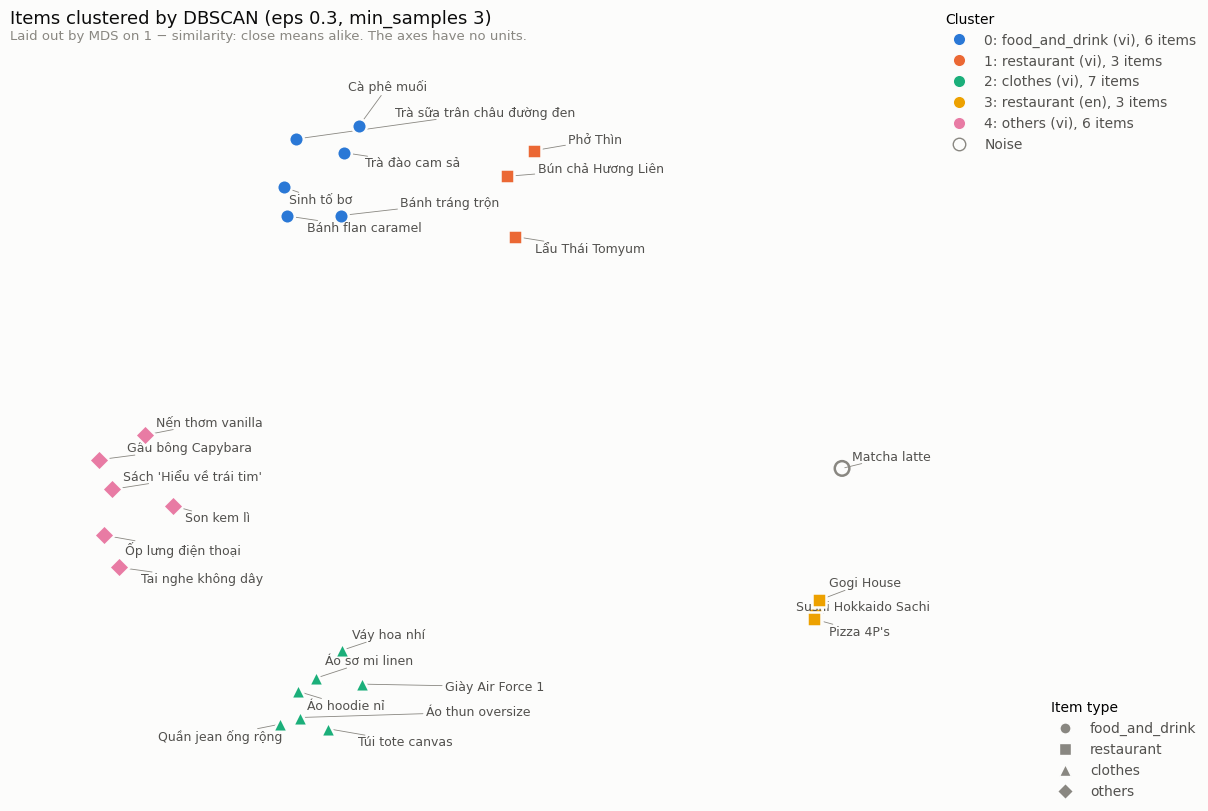

In [12]:
import matplotlib.pyplot as plt
from adjustText import adjust_text
from matplotlib.lines import Line2D
from sklearn.manifold import MDS

SURFACE, INK, INK_SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
# One colour per cluster, in this order (never cycled: a 9th cluster needs another way to show it)
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TYPE_MARKERS = {"food_and_drink": "o", "restaurant": "s", "clothes": "^", "others": "D"}
assert items["cluster"].max() < len(CLUSTER_COLORS)

xy = MDS(n_components=2, metric="precomputed", init="classical_mds", random_state=0).fit_transform(distance)


def cluster_name(c):
    if c == -1:
        return "Noise"
    members = items[items["cluster"] == c]
    return f"{c}: {members['item_type'].mode()[0]} ({', '.join(sorted(set(members['lang'])))}), {len(members)} items"


# Constrained layout keeps the legends beside the plot inside the figure
fig, ax = plt.subplots(figsize=(12, 8), facecolor=SURFACE, layout="constrained")
ax.set_facecolor(SURFACE)
labels = []
for i, row in items.iterrows():
    noise = row["cluster"] == -1
    ax.scatter(
        *xy[i], s=110, marker=TYPE_MARKERS[row["item_type"]], zorder=3,
        facecolors="none" if noise else CLUSTER_COLORS[row["cluster"]],
        edgecolors=MUTED if noise else SURFACE, linewidths=1.8,
    )
    labels.append(ax.text(*xy[i], row["item_name"], fontsize=9, color=INK_SECONDARY))

clusters = sorted(items["cluster"].unique(), key=lambda c: (c == -1, c))
cluster_keys = [
    Line2D([], [], ls="", marker="o", ms=9, mfc="none" if c == -1 else CLUSTER_COLORS[c], mec=MUTED if c == -1 else SURFACE, label=cluster_name(c))
    for c in clusters
]
type_keys = [Line2D([], [], ls="", marker=m, ms=8, mfc=MUTED, mec=SURFACE, label=t) for t, m in TYPE_MARKERS.items()]
legend_style = dict(frameon=False, labelcolor=INK_SECONDARY, alignment="left")
fig.legend(handles=cluster_keys, title="Cluster", loc="outside right upper", **legend_style)
fig.legend(handles=type_keys, title="Item type", loc="outside right lower", **legend_style)

ax.set_title(f"Items clustered by DBSCAN (eps {EPS}, min_samples {MIN_SAMPLES})", loc="left", color=INK, fontsize=13, pad=22)
ax.text(0, 1.02, "Laid out by MDS on 1 − similarity: close means alike. The axes have no units.", transform=ax.transAxes, color=MUTED, fontsize=9.5)
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.margins(0.12)
# Names pushed apart where items sit close together, with a line back to their point
adjust_text(labels, x=xy[:, 0], y=xy[:, 1], ax=ax, expand=(1.4, 1.8), arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
plt.show()

## What each cluster says about their taste (Gemma 4)

For each cluster, Gemma 4 (`gemma-4-31b-it`, through the Gemini API) gets the purchases of its items, with their details, scores and reviews, and sums up what they like. Noise isn't summed up: it's one item at most here. Needs `GEMINI_API_KEY` in `ai-notebooks/.env` (a key from https://aistudio.google.com/apikey); git ignores that file.

In [15]:
import os

from dotenv import load_dotenv
from google import genai
from IPython.display import Markdown, display

# The key in ai-notebooks/.env, over whatever the kernel already has: an older value from before the
# file was edited, or a GOOGLE_API_KEY, which the client would otherwise take first
load_dotenv(".env", override=True)
api_key = os.getenv("GEMINI_API_KEY")
if not api_key:
    raise RuntimeError("Put GEMINI_API_KEY=... in ai-notebooks/.env (a key from https://aistudio.google.com/apikey)")
# Masked: enough to tell it loaded and which key it is, without the key landing in the notebook
print(f"GEMINI_API_KEY loaded: {api_key[:4]}…{api_key[-4:]} ({len(api_key)} characters)")

client = genai.Client(api_key=api_key)
GEMMA = "gemma-4-26b-a4b-it"

# The item's own fields worth telling the model, where it has them
DETAILS = ["size", "color", "brand", "sugar", "toppings", "notes", "category", "main_food", "cuisine_type", "address", "time_to_eat"]


def purchase_line(row):
    """One purchase as a line for the prompt: the item, its details, and its rating if it has one"""
    details = []
    for field in DETAILS:
        value = row[field]
        if isinstance(value, list):
            value = ", ".join(value)
        if isinstance(value, str) and value:
            details.append(f"{field}: {value}")
    line = f"- {row['item_name']} ({row['item_type']}" + (f"; {'; '.join(details)}" if details else "") + ")"
    if pd.isna(row["score"]):
        return f"{line}: for {row['owner']}, not rated"
    review = f': "{row["content"]}"' if isinstance(row["content"], str) and row["content"] else ""
    return f"{line}: {row['owner']} rated it {row['score']}/5{review}"


PROMPT = """These are things a couple, lan and minh, bought, all from one group of similar items, with how the one who
wanted each rated it (1 to 5) and what they wrote (in Vietnamese).

{purchases}

In 2 or 3 sentences, in English, sum up what they like in this group: which kinds, flavours, styles or places
they rate highly, and what they rate lower. Say who likes what where lan and minh differ. Use only what's above."""


def cluster_prompt(c):
    names = items.loc[items["cluster"] == c, "item_name"]
    purchases = history[history["item_name"].isin(names)].sort_values("time")
    return PROMPT.format(purchases="\n".join(purchase_line(row) for _, row in purchases.iterrows()))

GEMINI_API_KEY loaded: AQ.A…5GEA (53 characters)


In [16]:
summaries = {}
for c in sorted(set(items["cluster"]) - {-1}):
    response = client.models.generate_content(model=GEMMA, contents=cluster_prompt(c))
    summaries[c] = response.text.strip()
    display(Markdown(f"**{cluster_name(c)}**\n\n{summaries[c]}"))

**0: food_and_drink (vi), 6 items**

Both Lan and Minh highly rate the brown sugar pearl milk tea, but Minh also enjoys the avocado smoothie and peach orange lemongrass tea. Lan's ratings are more inconsistent, providing mixed or lower scores for the avocado smoothie, salt coffee, and bánh tráng trộn, while Minh rates the caramel flan more moderately.

**1: restaurant (vi), 3 items**

Minh highly rates both Vietnamese and Thai cuisine, specifically finding the Thai seafood hotpot perfect. Lan differs by rating the Thai seafood hotpot lower, finding it only okay, though she enjoys Vietnamese bún chả.

**2: clothes (vi), 7 items**

Both Lan and Minh rate hoodies and oversized t-shirts highly, though they differ on several other items. Lan highly rates the tote bags and floral dress, whereas Minh favors the Air Force 1 sneakers and wide-leg jeans. They disagree on the sneakers, which Lan finds average, and the tote bags, which Minh rates poorly.

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}